In M124 HW09 we use `using PyCall, PyPlot   # Packages needed`
```julia
    @pyimport IPython.display as d
    function anim(sol::IVPsolution)
        animation = pyimport("matplotlib.animation");
        fig, ax = subplots(figsize=(5,5))
        function update(frame)
            θ1 = sol.y[frame+1,1]
            θ2 = sol.y[frame+1,2]
            p1 = [sin(θ1),-cos(θ1)]
            p2 = p1 .+ [sin(θ2),-cos(θ2)]
            ax.clear()
            ax.plot([0,p1[1],p2[1]], [0,p1[2],p2[2]], linewidth=2)
            ax.add_artist(matplotlib.patches.Circle(p1, 0.1))
            ax.add_artist(matplotlib.patches.Circle(p2, 0.1))
            ax.set_xlim([-2.5,2.5])
            ax.set_ylim([-2.5,2.5])
        end

        ani = animation.FuncAnimation(fig, update, frames=length(sol.t), interval=50)
        close(ani._fig)
        d.HTML(ani.to_jshtml())
    end
```
But I remember we move to `Plots` Thus, I will find a UI which match Plots later....

In [1]:
include("../src/load_all.jl")

Loaded successfully.


In [ ]:
case_FVM = LaxCase.make_case(; nx=20, ny=2, degree=0, final_time=1,
                   OF=false, characteristic=false, 
                   positivity=false, 
                   cfl=0.3, 
                   max_retries=5
                   )

solution_FVM = Solver.raw_solve_2d(case_FVM; time_method=:SSPRK3, verbose=true, save_every=50, dt_max=case_FVM.final_time/20)
# (solution.time, solution.number_of_steps, solution.number_of_retries)

step=1 time=0.0037224861056497564 dt=0.0037224861056497564 retries=0
step=2 time=0.007431825916865257 dt=0.003709339811215501 retries=0
step=3 time=0.011128401829903078 dt=0.0036965759130378213 retries=0
step=4 time=0.014812580630172736 dt=0.003684178800269658 retries=0
step=5 time=0.01848471438942395 dt=0.0036721337592512155 retries=0
step=6 time=0.022145141298190906 dt=0.0036604269087669554 retries=0
step=7 time=0.02579418643899489 dt=0.0036490451408039844 retries=0
step=8 time=0.029432162505266393 dt=0.0036379760662715024 retries=0
step=9 time=0.03305937047046788 dt=0.0036272079652014838 retries=0
step=10 time=0.03667610021147152 dt=0.003616729741003641 retries=0
step=11 time=0.04028263108986562 dt=0.0036065308783941054 retries=0
step=12 time=0.04387923249452359 dt=0.0035966014046579743 retries=0
step=13 time=0.047466164348465276 dt=0.003586931853941686 retries=0
step=14 time=0.051043677582768086 dt=0.0035775132343028133 retries=0
step=15 time=0.054612014580040835 dt=0.0035683369972

(state = Main.States.DGState([5.708098050912943 6.216397506303644 … 14.500513582093923 15.000118550165558; 0.0 0.0 … 0.1 0.1], [0.011124999999999996 0.00850289171949959 -3.2986601468316595e-9 0.22182445511750998;;; 0.011124999999999996 0.009082283369634203 6.934331135784372e-19 0.22107938387306766;;; 0.011124999999999996 0.009909925298064157 -1.1847696357332899e-18 0.21981504546895314;;; … ;;; 0.012499999999999992 0.0003666196666654922 0.0 0.036043120548749336;;; 0.012499999999999992 7.935660345928271e-5 0.0 0.03576166294382013;;; 0.012499999999999992 1.59018358503063e-5 1.1889453272002839e-12 0.03570239905749832]), case = Main.Discretization.DGCase{Main.LaxCase.LaxProblem}(Main.LaxCase.LaxProblem(:lax, false), Main.Meshes.Mesh([5.0, 15.0, 0.0, 0.1], 20, 2, [1 2 … 40 41; 2 3 … 41 42; 23 24 … 62 63; 22 23 … 61 62], Main.Meshes.Face[Main.Meshes.Face(2, 23, 1, 2, false, :interior, [0.0, 0.0]), Main.Meshes.Face(23, 22, 1, 21, false, :interior, [0.0, 0.0]), Main.Meshes.Face(22, 1, 1, 0, fal

In [ ]:
Diagnostics.conservation_report(solution_FVM)

(initial_total_ls = [0.4724999999999999, 0.15530499999999997, 0.0, 5.177951444999996], final_total_ls = [0.4724999999999999, 0.44954281513851857, -1.5134309363089408e-18, 5.426594220423058], change_ls = [0.0, 0.2942378151385186, -1.5134309363089408e-18, 0.248642775423062], boundary_change_ls = [0.0, 0.29423781513852393, -1.5134294075684923e-18, 0.2486427754231604], balance_error_ls = [0.0, -5.329070518200751e-15, -1.5287404484496035e-24, -9.83935155574045e-14])

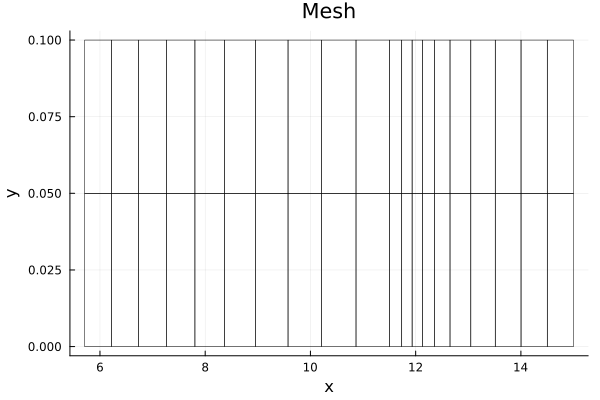

In [5]:
display(Visualization.plot_mesh(solution_FVM.state,case_FVM.mesh))

[ Info: Saved animation to c:\Users\Peikai_Li\Desktop\lagrangian_ofdg_2d_simple_release\results\LaxCasedensitywith_degree=0.gif


Plots.AnimatedGif("c:\\Users\\Peikai_Li\\Desktop\\lagrangian_ofdg_2d_simple_release\\results\\LaxCasedensitywith_degree=0.gif")
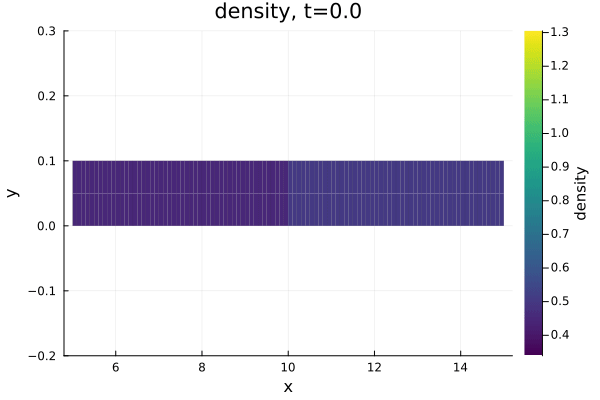

[ Info: Saved animation to c:\Users\Peikai_Li\Desktop\lagrangian_ofdg_2d_simple_release\results\LaxCasepressurewith_degree=0.gif


Plots.AnimatedGif("c:\\Users\\Peikai_Li\\Desktop\\lagrangian_ofdg_2d_simple_release\\results\\LaxCasepressurewith_degree=0.gif")
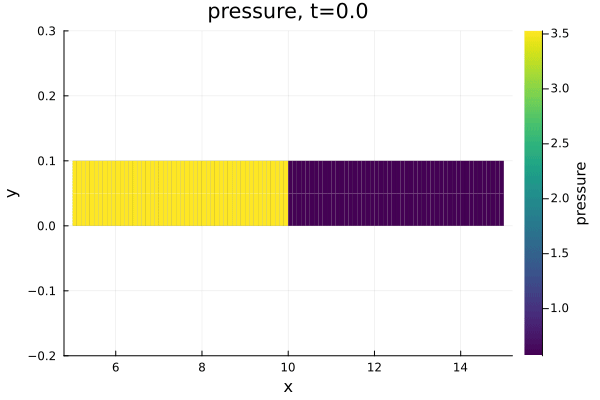

[ Info: Saved animation to c:\Users\Peikai_Li\Desktop\lagrangian_ofdg_2d_simple_release\results\LaxCasevelocity_xwith_degree=0.gif


Plots.AnimatedGif("c:\\Users\\Peikai_Li\\Desktop\\lagrangian_ofdg_2d_simple_release\\results\\LaxCasevelocity_xwith_degree=0.gif")
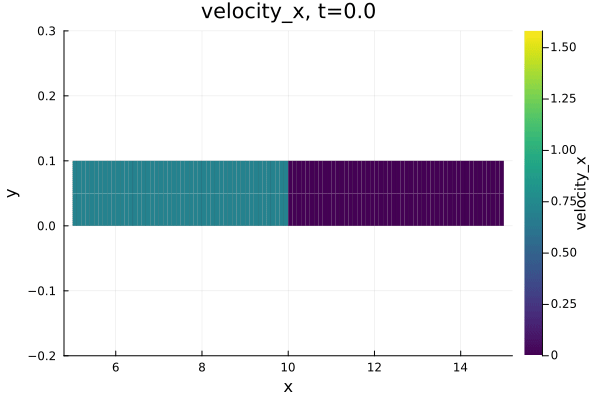

[ Info: Saved animation to c:\Users\Peikai_Li\Desktop\lagrangian_ofdg_2d_simple_release\results\LaxCasevelocity_ywith_degree=0.gif


Plots.AnimatedGif("c:\\Users\\Peikai_Li\\Desktop\\lagrangian_ofdg_2d_simple_release\\results\\LaxCasevelocity_ywith_degree=0.gif")
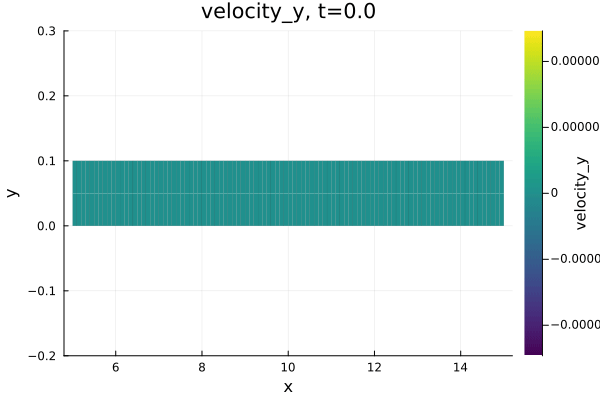

In [ ]:
for field in (:density, :pressure, :velocity_x, :velocity_y)
    gif_result = Visualization.draw_gif(
        solution_FVM,
        "../results/LaxCase$(field)with_degree=0.gif";
        field = field,
        fps = 10,
    )
    display(gif_result)
end
# plot this is very very slow!!!!!!!!!!!

## Try to directly use the original method on this lax problem for fun

In [6]:
case_test = LaxCase.make_case(nx=100, ny=2, degree=1, final_time=0.2)
solution = Solver.raw_solve_2d(case_test; time_method=:SSPRK3, verbose=true, save_every=10, dt_max=case_test.final_time/20)
(solution.time, solution.number_of_steps, solution.number_of_retries)

step=1 time=0.0037224861056497555 dt=0.0037224861056497555 retries=0
Rejected trial: time=0.0037224861056497555, dt=0.0036528153112023016, reason=DomainError with 51:
nonphysical polynomial value at point=(10.097169541099175, 0.005000000000000006): rho=0.444551441070841, p=-0.012067153624855586
step=2 time=0.005548893761250906 dt=0.0018264076556011508 retries=1
Rejected trial: time=0.005548893761250906, dt=0.0036175514816129783, reason=DomainError with 51:
nonphysical polynomial value at point=(10.092215652663981, 0.022182458365519676): rho=0.4718275019202066, p=-0.008531610267795657
step=3 time=0.0073576695020573955 dt=0.0018087757408064892 retries=1
Rejected trial: time=0.0073576695020573955, dt=0.0035826753671374463, reason=DomainError with 51:
nonphysical polynomial value at point=(10.091017114181732, 0.02218245836553974): rho=0.5011905021649132, p=-0.06296224280850973
Rejected trial: time=0.0073576695020573955, dt=0.0017913376835687232, reason=DomainError with 51:
nonphysical poly

LoadError: DomainError with 51:
nonphysical polynomial value at point=(10.097521079332237, 0.0): rho=0.46633136411172244, p=-0.0024372583804101893

[ Info: Saved animation to c:\Users\Peikai_Li\Desktop\lagrangian_ofdg_2d_simple_release\results\LaxCasedensitywith_P2.gif


Plots.AnimatedGif("c:\\Users\\Peikai_Li\\Desktop\\lagrangian_ofdg_2d_simple_release\\results\\LaxCasedensitywith_P2.gif")
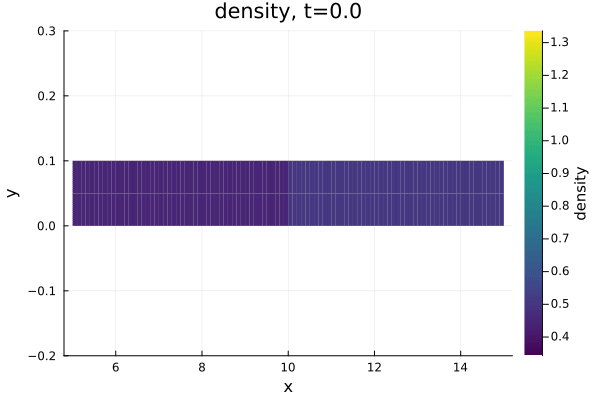

[ Info: Saved animation to c:\Users\Peikai_Li\Desktop\lagrangian_ofdg_2d_simple_release\results\LaxCasepressurewith_P2.gif


Plots.AnimatedGif("c:\\Users\\Peikai_Li\\Desktop\\lagrangian_ofdg_2d_simple_release\\results\\LaxCasepressurewith_P2.gif")
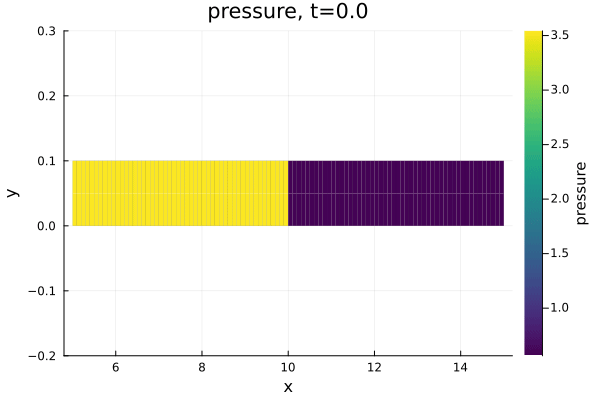

[ Info: Saved animation to c:\Users\Peikai_Li\Desktop\lagrangian_ofdg_2d_simple_release\results\LaxCasevelocity_xwith_P2.gif


Plots.AnimatedGif("c:\\Users\\Peikai_Li\\Desktop\\lagrangian_ofdg_2d_simple_release\\results\\LaxCasevelocity_xwith_P2.gif")
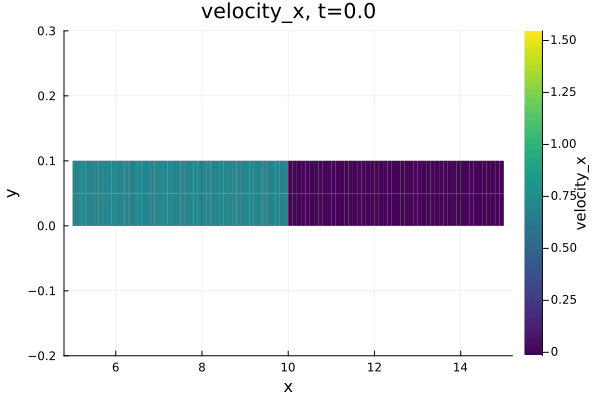

[ Info: Saved animation to c:\Users\Peikai_Li\Desktop\lagrangian_ofdg_2d_simple_release\results\LaxCasevelocity_ywith_P2.gif


Plots.AnimatedGif("c:\\Users\\Peikai_Li\\Desktop\\lagrangian_ofdg_2d_simple_release\\results\\LaxCasevelocity_ywith_P2.gif")
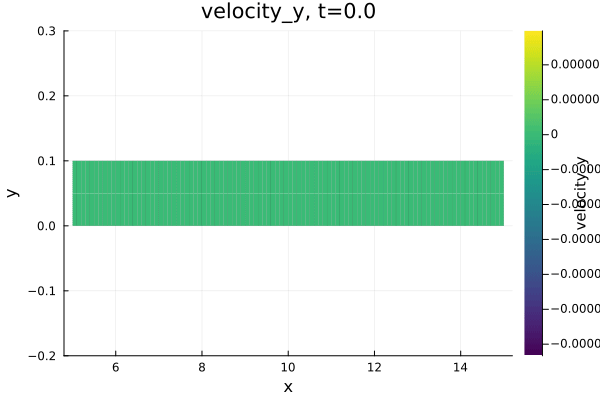

In [ ]:
caseP2 = LaxCase.make_case(; nx=100, ny=2, degree=2, final_time=1,
                   OF=true, characteristic=true, 
                   positivity=false, 
                   cfl=0.3, 
                   max_retries=1
                   )
solution_P2 = Solver.raw_solve_2d(caseP2; time_method=:SSPRK3, verbose=false, save_every=10, dt_max=caseP2.final_time/20)
(solution_P2.time, solution_P2.number_of_steps, solution_P2.number_of_retries)
println(solution_P2.number_of_retries)
for field in (:density, :pressure, :velocity_x, :velocity_y)
    gif_result = Visualization.draw_gif(
        solution_P2,
        "../results/LaxCase$(field)with_P2.gif";
        field = field,
        fps = 5,
    )
    display(gif_result)
end

### I accidently find a very weird result.

In [7]:
case_test2 = LaxCase.make_case(nx=10, ny=2, degree=2, final_time=0.2)
solution_test2 = Solver.raw_solve_2d(case_test2; time_method=:SSPRK3, verbose=true, save_every=10, dt_max=case_test2.final_time/20)
(solution_test2.time, solution_test2.number_of_steps, solution_test2.number_of_retries)

step=1 time=0.0037224861056497555 dt=0.0037224861056497555 retries=0
step=2 time=0.007438468795187362 dt=0.003715982689537607 retries=0
step=3 time=0.011148224246714616 dt=0.003709755451527253 retries=0
step=4 time=0.014851961822931723 dt=0.003703737576217108 retries=0
step=5 time=0.018549832335893288 dt=0.0036978705129615632 retries=0
step=6 time=0.022241936623502573 dt=0.0036921042876092835 retries=0
step=7 time=0.025928332924073757 dt=0.0036863963005711845 retries=0
step=8 time=0.02960904423285528 dt=0.0036807113087815244 retries=0
step=9 time=0.033284064128403304 dt=0.003675019895548022 retries=0
step=10 time=0.03695336197541926 dt=0.0036692978470159628 retries=0
step=11 time=0.04061688801776895 dt=0.0036635260423496844 retries=0
step=12 time=0.044274577756739195 dt=0.003657689738970245 retries=0
step=13 time=0.047926355631908085 dt=0.0036517778751688937 retries=0
step=14 time=0.05157213815734895 dt=0.0036457825254408616 retries=0
step=15 time=0.055211838176415375 dt=0.003639700019

(0.2, 58, 2)

[ Info: Saved animation to c:\Users\Peikai_Li\Desktop\lagrangian_ofdg_2d_simple_release\results\LaxCasedensitywith_degree=2solution_test2.gif


Plots.AnimatedGif("c:\\Users\\Peikai_Li\\Desktop\\lagrangian_ofdg_2d_simple_release\\results\\LaxCasedensitywith_degree=2solution_test2.gif")
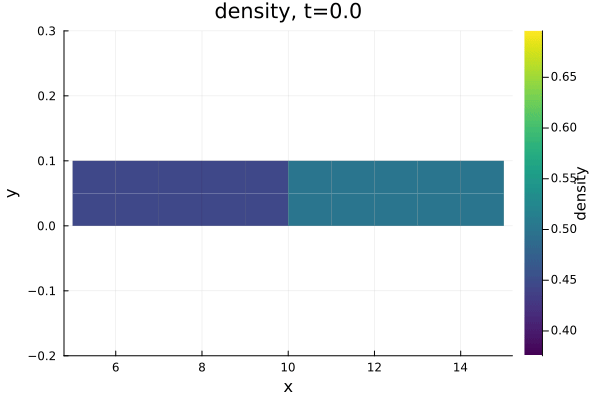

[ Info: Saved animation to c:\Users\Peikai_Li\Desktop\lagrangian_ofdg_2d_simple_release\results\LaxCasepressurewith_degree=2solution_test2.gif


Plots.AnimatedGif("c:\\Users\\Peikai_Li\\Desktop\\lagrangian_ofdg_2d_simple_release\\results\\LaxCasepressurewith_degree=2solution_test2.gif")
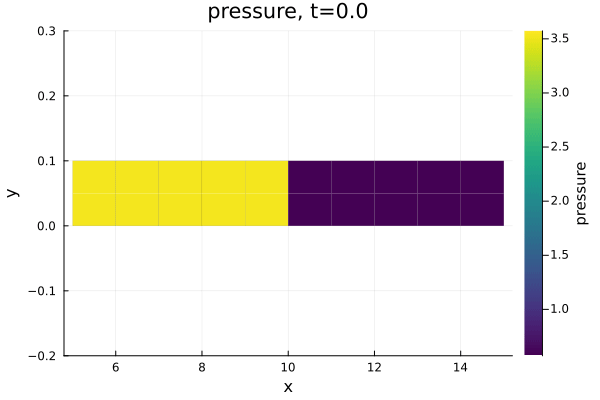

[ Info: Saved animation to c:\Users\Peikai_Li\Desktop\lagrangian_ofdg_2d_simple_release\results\LaxCasevelocity_xwith_degree=2solution_test2.gif


Plots.AnimatedGif("c:\\Users\\Peikai_Li\\Desktop\\lagrangian_ofdg_2d_simple_release\\results\\LaxCasevelocity_xwith_degree=2solution_test2.gif")
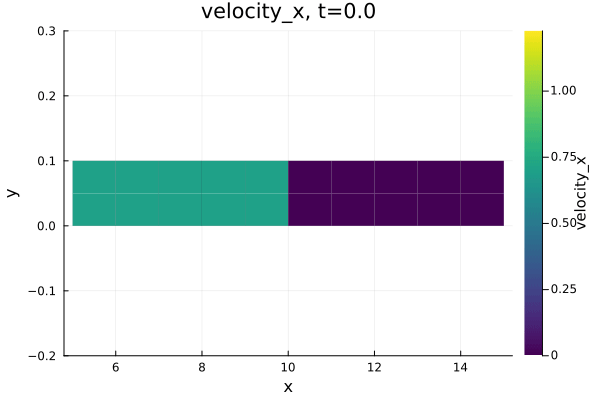

[ Info: Saved animation to c:\Users\Peikai_Li\Desktop\lagrangian_ofdg_2d_simple_release\results\LaxCasevelocity_ywith_degree=2solution_test2.gif


Plots.AnimatedGif("c:\\Users\\Peikai_Li\\Desktop\\lagrangian_ofdg_2d_simple_release\\results\\LaxCasevelocity_ywith_degree=2solution_test2.gif")
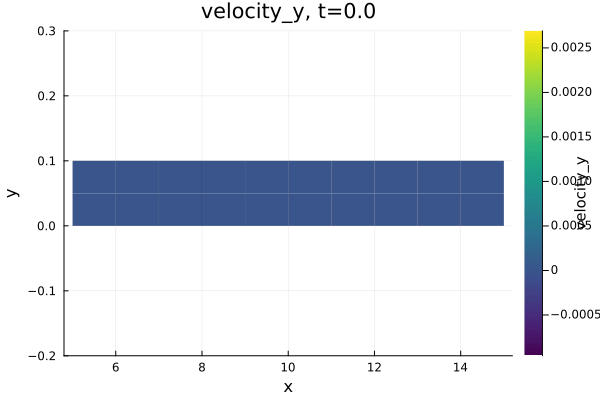

In [8]:
for field in (:density, :pressure, :velocity_x, :velocity_y)
    gif_result = Visualization.draw_gif(
        solution_test2,
        "../results/LaxCase$(field)with_degree=2solution_test2.gif";
        field = field,
        fps = 5,
    )
    display(gif_result)
end